(quickstart)=
# Quick start

Which genes does a stimulation change in each cell type, in a way that holds for other
donors and not only for the cells that were measured? This page answers that question
for a simulated study, from the cells to a result whose origin can be checked. It pools
the cells of every sample and cell type into a cube of pseudobulk profiles, tests the
stimulation in every cell type with limma-voom, and traces a result back to the
profiles and the cube it came from. Each step agrees with the package it follows
([Validation](validation.md)), and [Why pseudobulk](why_pseudobulk.ipynb) shows why the
tests compare samples, not cells.

The study is the simulated PBMC dataset ([Datasets](reference/datasets.md)): 12 donors,
each sampled before and after a stimulation, 19,151 cells of six cell types over 2,000
genes, with changes planted in every cell type. In a clone of the repository,
`uv run --group docs python docs/datasets.py prepare simulated_pbmc` writes its files,
which the code opens by name. The figures need CytePool's `plot` extra
([Installation](installation.md)). The code runs in a few seconds; the first run in a
new environment also compiles CytePool's numerical routines, which takes about half a
minute, once.

## Pool the cells into a cube

{api}`from_cells` sums the counts of the cells of every sample and cell type into one
profile, and records how many cells it pooled into each. It takes a cells x genes
matrix of counts, dense or sparse in the CSR layout in which an AnnData's `X` usually
holds them, the sample and the cell type of every cell, and a table of the samples,
here the donor and the condition of each, which stays with the cube.

CytePool 0.1.dev57+gb65bc7e32
Cube with 24 samples x 6 groups x 2,000 features
  layers: counts (uint32), detected (uint32), log_sum (float64), log_sum_sq (float64), linear_sum (float64)
  filled: 144 of 144 sample x group entries have cells (100.0%)
  samples: sample_id, donor, condition
  groups: group_id
  features: feature_id


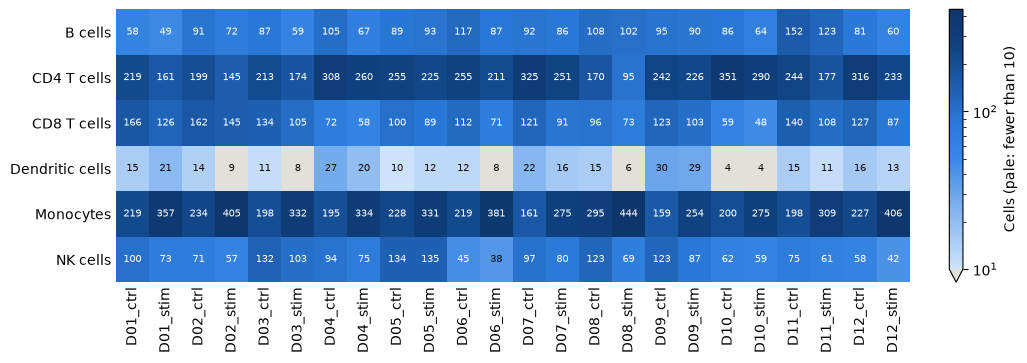

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.sparse

import cytepool
from cytepool.cube import from_cells
from cytepool.design import Design
from cytepool.differential_expression import limma_voom
from cytepool.io import read_cube, write_cube
from cytepool.plotting import plot_cell_numbers, plot_significant_genes, plot_volcano

cells = np.load("simulated_pbmc_cells.npz")
counts = scipy.sparse.csr_array(
    (cells["data"], cells["indices"], cells["indptr"]), shape=tuple(cells["shape"])
)
sample_ids = np.unique(cells["cell_sample"])
cube = from_cells(
    counts,
    samples=cells["cell_sample"],
    groups=cells["cell_type"],
    sample_table={
        "sample_id": sample_ids,
        "donor": [sample.split("_")[0] for sample in sample_ids],
        "condition": [sample.split("_")[1] for sample in sample_ids],
    },
    features=cells["feature_id"],
)
print(f"CytePool {cytepool.__version__}")
print(cube)
plot_cell_numbers(cube)
plt.show()

The profiles pool from 4 to 444 cells. A profile of a few cells is noisy, so
{api}`limma_voom` leaves the profiles of fewer than 10 cells out of their cell type's
fit: the six pale entries, all of them dendritic cells.

## Test every cell type

Every donor gives a control and a stimulated sample. The design `~ donor + condition`
compares the two samples of each donor, so that the differences between donors do not
count as noise, and its coefficient `conditionstim` is the log2 fold change of the
stimulation. {api}`limma_voom` then takes one cell type at a time: it keeps the genes
with enough counts, normalizes the libraries by TMM, gives every observation a voom
precision weight, fits the design to every gene and moderates the contrast by empirical
Bayes [@law2014; @ritchie2015].

DifferentialExpressionResult (limma_voom): 6 groups, 6 fitted; 1 contrast: stim_vs_ctrl
  B cells: 24 samples, 1951 features
  CD4 T cells: 24 samples, 1998 features
  CD8 T cells: 24 samples, 1974 features
  Dendritic cells: 18 samples, 1498 features
  Monocytes: 24 samples, 1997 features
  NK cells: 24 samples, 1918 features


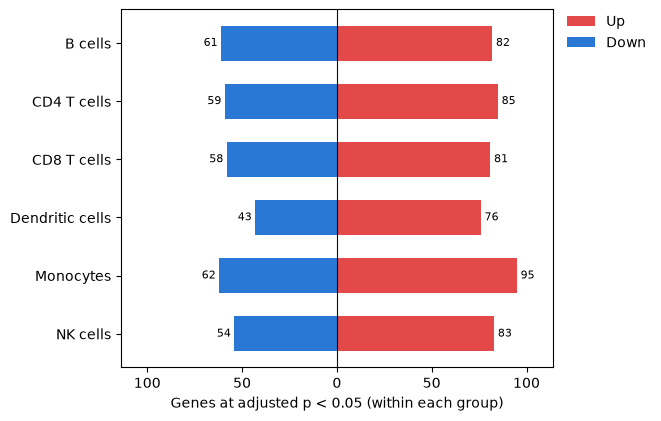

In [2]:
design = Design(
    cube.samples,
    "~ donor + condition",
    levels={"condition": ["ctrl", "stim"]},
    contrasts={"stim_vs_ctrl": "conditionstim"},
)
result = limma_voom(cube, design)
print(result)
plot_significant_genes(result)
plt.show()

The simulation changed 140 genes in each cell type, and about as many are called in
each. The dendritic cells, fitted on their 18 profiles of 10 cells or more, have the
fewest calls.

## The genes of one cell type

Each cell type and contrast has a table of its genes with the columns of limma's
`topTable` ({api}`DifferentialExpressionResult.table`). The volcano plot shows their
p-values against their fold changes and names the genes with the smallest p-values;
the table converts to a pandas DataFrame for sorting and export.

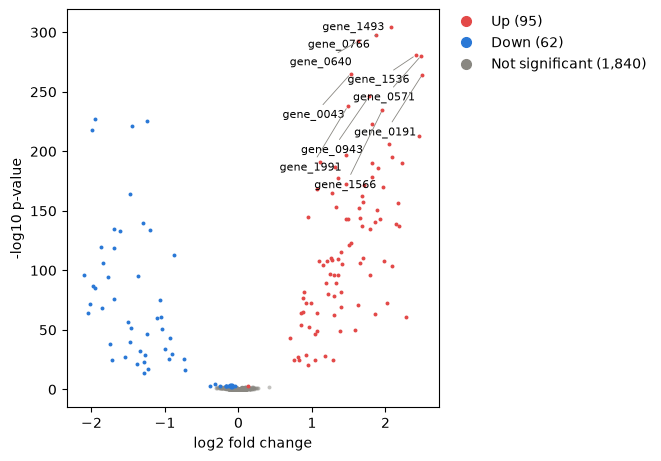

,log2_fold_change,average_log2_cpm,t,adjusted_p_value
feature_id,,,,
gene_1493,2.07,11.5,96.4,1.6e-301
gene_0766,1.87,11.9,93,3.99e-295
gene_0640,1.62,12.6,90.5,2.77e-290
gene_1536,2.41,10.3,85.1,9.77e-279
gene_0571,2.49,10.2,84.9,1.72e-278


In [3]:
table = result.table("Monocytes", "stim_vs_ctrl")
plot_volcano(table)
plt.show()
columns = ["log2_fold_change", "average_log2_cpm", "t", "adjusted_p_value"]
top = table.to_pandas().sort_values("p_value").set_index("feature_id")[columns]
top.head().map("{:.3g}".format)

## Trace a result back to its cube

Every result keeps a record of what produced it: the method and its settings, the
versions of CytePool, numpy, numba and Python, the design, and the cube, named by its
fingerprint, a digest of every value it holds. For every cell type the record lists the
profiles that entered the fit, and those left out with the reason. {api}`write_cube`
saves the cube and {api}`read_cube` opens it, on this machine or another, without
reading its counts; its fingerprint then says whether it is the cube the result was
computed from.

In [4]:
write_cube(cube, "pbmc.cube.zarr")
opened = read_cube("pbmc.cube.zarr")
record = result.provenance
print("computed from the cube", record["cube"]["fingerprint"])
print(
    "the saved file holds that cube:",
    opened.fingerprint() == record["cube"]["fingerprint"],
)
dendritic = next(
    fit for fit in record["groups"] if fit["group_id"] == "Dendritic cells"
)
print(f"Dendritic cells: {len(dendritic['samples'])} profiles fitted, left out:")
for sample, reason in dendritic["left_out"].items():
    print(f"  {sample}: {reason}")

computed from the cube sha256:1ec128cf0fb164a6c39ce11aef964d237b81ec6c87fa06b5ab44eebcff052438
the saved file holds that cube: True
Dendritic cells: 18 profiles fitted, left out:
  D02_stim: 9 cells, fewer than min_cells (10)
  D03_stim: 8 cells, fewer than min_cells (10)
  D06_stim: 8 cells, fewer than min_cells (10)
  D08_stim: 6 cells, fewer than min_cells (10)
  D10_ctrl: 4 cells, fewer than min_cells (10)
  D10_stim: 4 cells, fewer than min_cells (10)


## Next steps

- [Why pseudobulk](why_pseudobulk.ipynb): what goes wrong when cells are tested as
  replicates, and what benchmarks and replication studies found.
- [Pool cells into pseudobulk profiles](guides/pool_cells.ipynb): samples, cell types
  and layers, merged cell types, the dot plot of markers and the PCA of samples.
- [Save, share and trace cubes](guides/save_and_trace_cubes.ipynb): cube files,
  fingerprints and provenance records in full.
- [Genes that change in each cell type](guides/genes_per_cell_type.ipynb): the same
  analysis on published data, with the choices it involves.
- [Choosing a method](statistics/choosing_a_method.md): which function answers which
  question, for which design.